# Routes on a multimodal network

A **multimodal network** joins several transport networks: roads, railways, sea lanes and flights. A route on it can start on a road, take a ship or a flight, and end on a road.

scgraph publishes such networks. They are built from OpenStreetMap and other open sources. This notebook loads one of them, `oceania`, and shows how to use it:

1. Load the network.
2. Compute a first route and draw it.
3. See which kinds of transport the route uses.
4. Look at the whole network on a map.
5. Choose the modes that a route may use, with three examples.
6. Two limit cases: two places with no route between them, and a place far from the network.

The first run downloads the network (9.2 MB). After the download, the whole notebook runs in less than one minute.

The route maps are static figures. The map of the whole network also comes as an interactive map: zoom in to see its detail. GitHub does not show interactive maps. To see it, run the notebook, or open it in [nbviewer](https://nbviewer.org/github/connor-makowski/scgraph/blob/main/examples/multimodal_networks.ipynb).

## Setup

The notebook needs scgraph 4.0 or newer. It draws the static maps with [cartopy](https://scitools.org.uk/cartopy/) and [matplotlib](https://matplotlib.org), and the interactive map with [folium](https://python-visualization.github.io/folium/).

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" cartopy matplotlib folium
import collections

import cartopy.crs as ccrs
import cartopy.feature
import folium
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from scgraph import GeoGraph, PathNotFoundError, network_file
from scgraph.utils import haversine

## 1. Load the network

`load_geograph` loads a network by its name. The first call downloads the file and keeps it in a cache. Later calls read the cache.

`oceania` covers the latitudes -50 to 0 and the longitudes 110 to 180. It holds the main roads and the railways inside this rectangle. It also holds every sea lane, port and airport of the world, so a route can leave the rectangle by sea or by air.

In [2]:
oceania = GeoGraph.load_geograph("oceania")

info = GeoGraph.get_scgraph_info(oceania.scgraph_file)
print(f"{info['nodes']:,} nodes and {info['arcs']:,} arcs. The lengths are in {info['units']}.")
print("Newest source data:", info["data_up_to"])
print("Credit to cite with your results:", info["attribution"])

125,567 nodes and 338,274 arcs. The lengths are in km.
Newest source data: 2026-11-02T00:59:53Z
Credit to cite with your results: Eurostat, SeaRoute maritime network (from the Oak Ridge National Laboratory Global Shipping Lane Network, 2000, enriched with AIS-based lines around European coasts) (EUPL-1.2); Natural Earth (1:10m) (LicenseRef-public-domain); National Geospatial-Intelligence Agency, World Port Index (Pub. 150) (LicenseRef-US-Government-Work); OurAirports (LicenseRef-public-domain); The OpenSky Network, flight list (Strohmeier et al., Earth Syst. Sci. Data 13, 357-366, 2021); US Bureau of Transportation Statistics, T-100 Segment; Eurostat, air transport routes (avia_par, avia_gor) (CC-BY-4.0); Wikidata (CC0-1.0); © OpenStreetMap contributors (ODbL-1.0)


A **node** is a point of the network. An **arc** goes from one node to another, and has a length.

Each node has a **mode**. The mode says which network the node belongs to:

In [3]:
mode_names = [mode["name"] for mode in oceania.modes]
nodes_per_mode = collections.Counter(mode_names[row] for row in oceania.node_modes)
for name in mode_names:
    print(f"{name:<14}{nodes_per_mode[name]:>7,} nodes")

road           72,711 nodes
rail            7,971 nodes
sea            40,066 nodes
port            3,167 nodes
airport         1,645 nodes
rail_terminal       7 nodes


`road`, `rail` and `sea` are the three networks. A port, an airport or a rail terminal is a **hub**: a place where a route can change network. A flight goes from one airport to another.

## 2. A first route: Sydney to Perth

A place is a latitude and a longitude. It does not need to be a node of the network: scgraph joins each place to the nearest node.

In [4]:
PLACES = {
    "Sydney": {"latitude": -33.8688, "longitude": 151.2093},
    "Perth": {"latitude": -31.9523, "longitude": 115.8613},
    "Melbourne": {"latitude": -37.8136, "longitude": 144.9631},
    "Hobart": {"latitude": -42.8821, "longitude": 147.3272},
    "Brisbane": {"latitude": -27.4698, "longitude": 153.0251},
    "Suva": {"latitude": -18.1248, "longitude": 178.4501},
    "Auckland": {"latitude": -36.8485, "longitude": 174.7633},
    "Port Moresby": {"latitude": -9.4438, "longitude": 147.1803},
}

route = oceania.get_shortest_path(
    origin_node=PLACES["Sydney"], destination_node=PLACES["Perth"]
)
print(f"Length: {route['length']:,.1f} km")
print(f"The route has {len(route['coordinate_path'])} points. The first three:")
print(route["coordinate_path"][:3])

Length: 3,311.7 km
The route has 319 points. The first three:
[[-33.8688, 151.2093], [-33.8666455, 151.2058386], [-33.866667, 151.2]]


`length` is the length of the shortest route, in km. `coordinate_path` is the list of the points of the route, each as `[latitude, longitude]`. It is enough to draw the route.

The function `add_map` below starts every static map of this notebook, with [cartopy](https://scitools.org.uk/cartopy/).

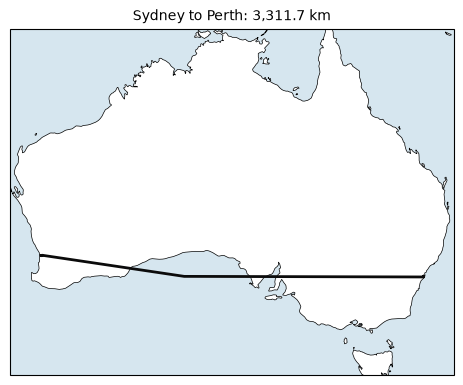

In [5]:
def add_map(figure, south, west, north, east, position=(1, 1, 1)):
    """Add to a figure a map of the area between two latitudes and two longitudes."""
    ax = figure.add_subplot(
        *position, projection=ccrs.PlateCarree(central_longitude=(west + east) / 2)
    )
    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    # The map fills the ocean, not the land: the land fill of cartopy fails on some regional maps
    ax.add_feature(cartopy.feature.OCEAN.with_scale("50m"), facecolor="#d6e6ef")
    ax.coastlines("50m", linewidth=0.5)
    return ax


AUSTRALIA = (-43, 113, -11, 154)

figure = plt.figure(figsize=(6, 4.5))
ax = add_map(figure, *AUSTRALIA)
latitudes, longitudes = zip(*route["coordinate_path"])
# Geodetic draws each step as a great circle, the line along which scgraph measures lengths
ax.plot(longitudes, latitudes, color="#0b0b0b", linewidth=2, transform=ccrs.Geodetic())
ax.set_title(f"Sydney to Perth: {route['length']:,.1f} km", fontsize=10)
plt.show()

The route is almost a straight line across the continent. No road is that straight. The next section shows what the route uses.

## 3. Which kinds of transport does the route use?

Each arc of the network has a **class**. The class says what the arc is: `motorway`, `primary`, `ferry`, `rail_main`, `open_sea`, `flight`, and so on. The file of the network holds the class of each arc. `network_file.read` reads it:

In [6]:
arrays, metadata = network_file.read(oceania.scgraph_file)

class_names = metadata["classes"]
arcs_per_class = collections.Counter(class_names[row] for row in arrays["arc_classes"])
print(f"The file names {len(class_names)} classes. The 12 classes with the most arcs:")
for name, count in arcs_per_class.most_common(12):
    print(f"    {name:<16}{count:>8,} arcs")

The file names 27 classes. The 12 classes with the most arcs:
    open_sea         152,660 arcs
    primary           56,384 arcs
    trunk             45,034 arcs
    flight            28,348 arcs
    rail_main         15,170 arcs
    trunk_link        10,215 arcs
    primary_link       7,134 arcs
    motorway_link      6,494 arcs
    sea_connector      6,334 arcs
    rail_other         4,518 arcs
    motorway           3,980 arcs
    rail_branch          880 arcs


A class whose name ends with `_connector` is a **connector**: an arc that joins a hub to one network. For example, a `road_connector` joins an airport to the nearest road.

This notebook groups the classes into six **kinds**, one for each line style of the maps: `road`, `ferry`, `rail`, `sea`, `flight` and `connector`.

The class `Network` below does the work for the rest of the notebook. It loads `oceania`, reads the kind and the length of each arc, and cuts a route into **sections**. A section is a part of the route where all the arcs have the same kind.

In [7]:
ROAD_CLASSES = {
    "motorway",
    "motorway_link",
    "trunk",
    "trunk_link",
    "primary",
    "primary_link",
    "shuttle_train",  # a train that carries road vehicles, as in the Channel Tunnel
}
HUB_MODES = {"port", "airport", "rail_terminal"}


def get_kind(class_name):
    """The kind of an arc, from the name of its class."""
    if class_name in ("flight", "ferry"):
        return class_name
    if class_name.endswith("_connector"):
        return "connector"
    if class_name.startswith("rail_"):
        return "rail"
    if class_name in ROAD_CLASSES:
        return "road"
    # `open_sea`, and the passages such as `suez` or `panama`
    return "sea"


def get_line(points):
    """The points of a line to draw on a map, each as [latitude, longitude].

    A line that crosses the meridian 180 goes on beyond 180. Without this, the line
    would jump to the other side of the map. The points are rounded to 0.00001
    degree, about 1 m, which keeps the maps light.
    """
    line = []
    for latitude, longitude in points:
        if line and abs(longitude - line[-1][1]) > 180:
            longitude += 360 if longitude < line[-1][1] else -360
        line.append([round(latitude, 5), round(longitude, 5)])
    return line


class Network:
    """The network `oceania`, or some of its modes, with the kind of each arc."""

    def __init__(self, modes=None):
        self.geograph = GeoGraph.load_geograph("oceania", modes=modes)
        arrays, metadata = network_file.read(self.geograph.scgraph_file, modes=modes)
        # The arcs that leave node `u` are the arcs offsets[u] to offsets[u + 1] - 1.
        # Arc `a` goes to the node heads[a].
        self.offsets, self.heads = arrays["offsets"], arrays["heads"]
        self.km = arrays["weights"]
        kinds = [get_kind(name) for name in metadata["classes"]]
        self.kinds = [kinds[row] for row in arrays["arc_classes"]]
        self.mode_names = [mode["name"] for mode in self.geograph.modes]

    def get_arc_points(self, origin, arc):
        """The points that draw an arc: its two nodes, and the points of its shape between them."""
        nodes, destination = self.geograph.nodes, self.heads[arc]
        shape = self.geograph.intermediate_nodes[origin].get(destination, [])
        return [nodes[origin], *shape, nodes[destination]]

    def get_route(self, origin, destination):
        """The shortest route between two places of `PLACES`, as scgraph returns it, with two more keys.

        `sections` is the list of the sections of the route. Each section is a dict with
        its `kind`, its length in `km` and its `line` to draw. The first and the last
        section have the kind `off network`: the straight line between a place and the
        node nearest to it.

        `hubs` is the list of the hubs that the route passes, each as (mode, point).
        """
        route = self.geograph.get_shortest_path(
            origin_node=PLACES[origin],
            destination_node=PLACES[destination],
            output_path=True,
        )
        points, path = route["coordinate_path"], route["path"]
        sections = [
            {
                "kind": "off network",
                "km": haversine(points[0], points[1]),
                "line": get_line(points[:2]),
            }
        ]
        # `path` is the list of the nodes of the route. Two nodes in a row are the ends of one arc.
        for node, next_node in zip(path, path[1:]):
            # Two arcs may join the same two nodes. The route uses the shortest one.
            arc = min(
                (
                    arc
                    for arc in range(self.offsets[node], self.offsets[node + 1])
                    if self.heads[arc] == next_node
                ),
                key=lambda arc: self.km[arc],
            )
            line = get_line(self.get_arc_points(node, arc))
            if sections[-1]["kind"] == self.kinds[arc]:
                sections[-1]["km"] += self.km[arc]
                sections[-1]["line"] += line[1:]
            else:
                sections.append({"kind": self.kinds[arc], "km": self.km[arc], "line": line})
        sections.append(
            {
                "kind": "off network",
                "km": haversine(points[-2], points[-1]),
                "line": get_line(points[-2:]),
            }
        )
        route["sections"] = sections
        modes = [self.mode_names[self.geograph.node_modes[node]] for node in path]
        route["hubs"] = [
            (mode, self.geograph.nodes[node])
            for mode, node in zip(modes, path)
            if mode in HUB_MODES
        ]
        return route

    def get_lines(self, south, west, north, east):
        """The arcs with a node between two latitudes and two longitudes, as lines to draw.

        Returns {kind: [line, ...]}. An arc and its reverse arc give one line. A line
        is straight from node to node, with points rounded to 0.001 degree: a map of
        a whole network stays light this way.
        """
        nodes = self.geograph.nodes
        is_inside = [
            south <= latitude <= north and west <= longitude <= east
            for latitude, longitude in nodes
        ]
        lines, drawn = collections.defaultdict(list), set()
        for origin in range(len(nodes)):
            for arc in range(self.offsets[origin], self.offsets[origin + 1]):
                destination = self.heads[arc]
                ends = (min(origin, destination), max(origin, destination))
                if (is_inside[origin] or is_inside[destination]) and ends not in drawn:
                    drawn.add(ends)
                    lines[self.kinds[arc]].append(
                        get_line(
                            [round(value, 3) for value in nodes[node]]
                            for node in (origin, destination)
                        )
                    )
        return lines


def print_route(title, route):
    """Print the length of a route, then its sections of 0.1 km or more."""
    print(f"{title}: {route['length']:,.1f} km")
    for section in route["sections"]:
        if section["km"] >= 0.05:
            print(f"    {section['kind']:<12}{section['km']:>9,.1f} km")

In [8]:
all_modes = Network()

route = all_modes.get_route("Sydney", "Perth")
print_route("Sydney to Perth", route)

Sydney to Perth: 3,311.7 km
    off network       0.4 km
    connector         1.0 km
    road             16.1 km
    connector         0.1 km
    flight        3,277.2 km
    connector         0.8 km
    road             16.2 km


The route takes a **flight** for 3,277 km. Before and after the flight, it uses roads, and connectors between a hub and a network. The lengths of the sections add up to the length of the route (the printed values are rounded).

This result shows an important rule. **The route is the shortest in kilometres.** scgraph does not count the time, the price, or the wait at an airport. [Issue #287](https://github.com/connor-makowski/scgraph/issues/287) tracks routing by time, cost and CO2. A flight is close to a straight line, so with all the modes, a long route nearly always takes a flight.

The next cell defines the function that draws routes with one line style for each kind.

In [9]:
STYLES = {
    "road": {"color": "#eb6834"},
    "ferry": {"color": "#eb6834", "linestyle": ":"},
    "rail": {"color": "#1baf7a"},
    "sea": {"color": "#2a78d6"},
    "flight": {"color": "#0b0b0b", "linestyle": "--"},
    "connector": {"color": "#52514e"},
    "off network": {"color": "#52514e", "linestyle": ":"},
}


def get_legend(kinds, has_hubs=False):
    """The legend entries of `kinds`, in the order of `STYLES`, then the entry of a hub if `has_hubs`."""
    entries = [
        plt.Line2D([], [], linewidth=2.5, label=kind, **style)
        for kind, style in STYLES.items()
        if kind in kinds
    ]
    if has_hubs:
        entries.append(
            plt.Line2D([], [], marker="o", color="#0b0b0b", markerfacecolor="#fcfcfb", linestyle="", label="hub")
        )
    return entries


def draw_route_map(south, west, north, east, routes, places):
    """A figure with one map for each route, between two latitudes and two longitudes.

    `routes` is a dict {title: route}, with routes of `Network.get_route`. Each
    section of a route is a line in the style of its kind. A white circle is a
    hub. `places` is a list of names of `PLACES`, marked on each map.
    """
    # The constrained layout keeps room for the legend under the maps
    figure = plt.figure(figsize=(4.2 * len(routes), 4.2), layout="constrained")
    kinds = set()
    for number, (title, route) in enumerate(routes.items(), start=1):
        ax = add_map(figure, south, west, north, east, position=(1, len(routes), number))
        for section in route["sections"]:
            if section["km"] >= 0.05:
                kinds.add(section["kind"])
                latitudes, longitudes = zip(*section["line"])
                ax.plot(longitudes, latitudes, linewidth=2.5, transform=ccrs.Geodetic(), **STYLES[section["kind"]])
        for mode, (latitude, longitude) in route["hubs"]:
            ax.plot(longitude, latitude, "o", color="#0b0b0b", markerfacecolor="#fcfcfb", transform=ccrs.PlateCarree())
        for name in places:
            point = PLACES[name]
            ax.plot(point["longitude"], point["latitude"], "ko", markersize=4, transform=ccrs.PlateCarree())
            ax.text(point["longitude"], point["latitude"], f"  {name}", fontsize=8, transform=ccrs.PlateCarree())
        ax.set_title(f"{title}: {route['length']:,.1f} km", fontsize=10)
    has_hubs = any(route["hubs"] for route in routes.values())
    figure.legend(handles=get_legend(kinds, has_hubs), loc="outside lower center", ncol=8, fontsize=8)
    return figure

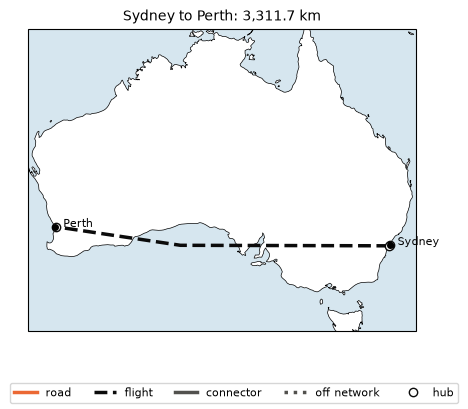

In [10]:
figure = draw_route_map(*AUSTRALIA, {"Sydney to Perth": route}, ["Sydney", "Perth"])
plt.show()

## 4. The whole network on a map

The next cell draws the railways, the vehicle ferries and the sea lanes of the network. It draws each arc that has a node inside the rectangle of `oceania`. It draws them twice: first on a static map, then on an interactive map.

On the interactive map, zoom in to see the detail. The control at the top right shows or hides each part of the network. Tick *Flights* to see the flights. The static map leaves the flights out, because they would hide the rest.

The roads are left out. They are 105,000 lines, too many for a map in a notebook. The route maps show the roads that a route uses.

road: 105,235 lines, connector: 419 lines, ferry: 196 lines, rail: 10,289 lines, sea: 1,221 lines, flight: 263 lines


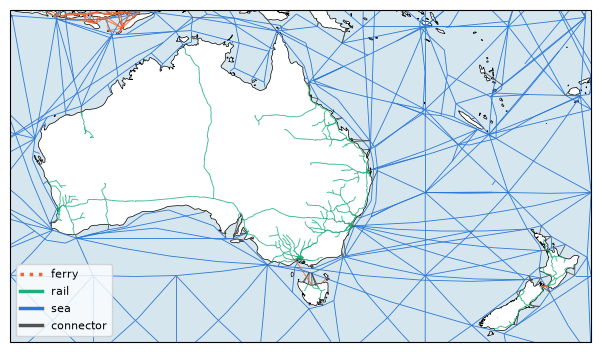

In [11]:
RECTANGLE = (-50, 110, 0, 180)  # south, west, north, east
lines = all_modes.get_lines(*RECTANGLE)
print(", ".join(f"{kind}: {len(kind_lines):,} lines" for kind, kind_lines in lines.items()))

# The static map. One collection holds all the arcs of a kind, as straight lines.
figure = plt.figure(figsize=(7.5, 4.6))
ax = add_map(figure, -48, 110, -8, 180)
for kind in ["sea", "connector", "rail", "ferry"]:
    segments = [[(longitude, latitude) for latitude, longitude in line] for line in lines[kind]]
    ax.add_collection(
        LineCollection(segments, color=STYLES[kind]["color"], linewidth=0.6, transform=ccrs.PlateCarree())
    )
ax.legend(handles=get_legend(["ferry", "rail", "sea", "connector"]), loc="lower left", fontsize=8)
plt.show()


# The interactive map
def make_map(south, west, north, east, height=440):
    """A new interactive map that shows the area between two latitudes and two longitudes."""
    new_map = folium.Map(tiles=None)
    # `control=False` keeps the background out of the control that shows or hides layers
    folium.TileLayer("OpenStreetMap", control=False).add_to(new_map)
    new_map.fit_bounds([[south, west], [north, east]])
    # The figure gives the map its height in the notebook
    folium.Figure(height=height).add_child(new_map)
    return new_map


layers = {
    "Railways": ["rail"],
    "Vehicle ferries": ["ferry"],
    "Sea lanes and connectors": ["sea", "connector"],
    "Flights": ["flight"],
}
network_map = make_map(-48, 110, -8, 180, height=560)
for name, kinds in layers.items():
    # The flights hide the rest of the map: their layer starts hidden
    layer = folium.FeatureGroup(name=name, show=name != "Flights")
    for kind in kinds:
        # One line object holds all the arcs of a kind
        folium.PolyLine(
            lines[kind],
            weight=1.5,
            opacity=0.4 if kind == "flight" else 0.9,
            color=STYLES[kind]["color"],
        ).add_to(layer)
    layer.add_to(network_map)
folium.LayerControl(collapsed=False).add_to(network_map)
network_map

The railways stop at the edges of the rectangle. The sea lanes and the flights go on to the rest of the world. On these maps, an arc is a straight line between its two nodes. A route map draws the true shape of each arc.

## 5. Choose the modes

`modes` gives the list of the modes to load. `load_geograph` then loads only the nodes of these modes, and the arcs between them. A route on this smaller network cannot use anything else.

### By road, or by road and sea

Two more ways from Sydney to Perth: by road only, and by road and sea. A port is the hub between the roads and the sea lanes. So the mode `port` is loaded with `road` and `sea`: without it, no arc joins the two networks.

In [12]:
roads = Network(modes=["road"])
roads_and_sea = Network(modes=["road", "sea", "port"])

routes = {
    "All modes": all_modes.get_route("Sydney", "Perth"),
    'modes=["road"]': roads.get_route("Sydney", "Perth"),
    'modes=["road", "sea", "port"]': roads_and_sea.get_route("Sydney", "Perth"),
}
for title, route in routes.items():
    print_route(title, route)

All modes: 3,311.7 km
    off network       0.4 km
    connector         1.0 km
    road             16.1 km
    connector         0.1 km
    flight        3,277.2 km
    connector         0.8 km
    road             16.2 km
modes=["road"]: 3,930.3 km
    off network       0.5 km
    road          3,929.7 km
modes=["road", "sea", "port"]: 3,737.0 km
    off network       0.5 km
    road          1,387.6 km
    connector         6.4 km
    sea           1,871.6 km
    connector        62.3 km
    road            408.5 km


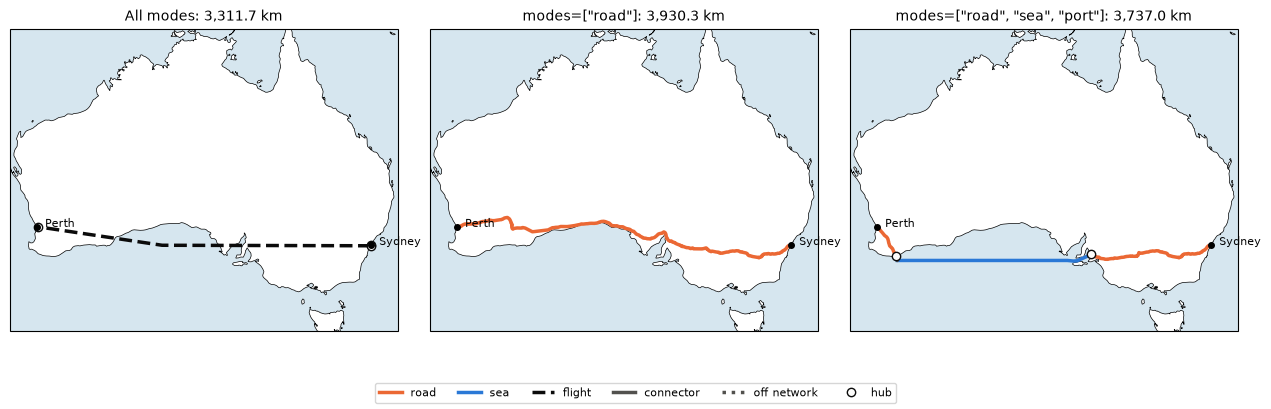

In [13]:
figure = draw_route_map(*AUSTRALIA, routes, ["Sydney", "Perth"])
plt.show()

The three routes answer three different questions. Choose the modes that fit your question. For example, load `road`, `sea` and `port` for a container, which does not take a flight.

### A ferry is a road: Hobart to Melbourne

Hobart is on an island, Tasmania. With all the modes, the route takes a flight. With `modes=["road"]`, there is still a route: a ferry that carries vehicles has the mode `road`. Its arcs have the class `ferry`.

All modes: 654.0 km
    off network       0.3 km
    road             19.9 km
    connector         2.1 km
    flight          609.6 km
    connector         0.9 km
    road             12.8 km
    connector         0.7 km
    rail              7.1 km
    off network       0.6 km
modes=["road"]: 778.8 km
    off network       0.3 km
    road            261.1 km
    ferry           448.7 km
    road             68.0 km
    off network       0.7 km


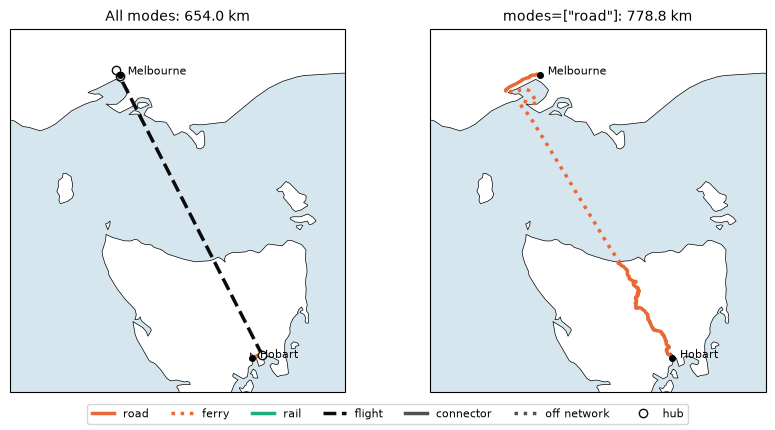

In [14]:
routes = {
    "All modes": all_modes.get_route("Hobart", "Melbourne"),
    'modes=["road"]': roads.get_route("Hobart", "Melbourne"),
}
for title, route in routes.items():
    print_route(title, route)

figure = draw_route_map(-43.5, 143, -37, 149, routes, ["Hobart", "Melbourne"])
plt.show()

### A route by sea: Brisbane to Suva

Suva is the capital of Fiji, an island country in the Pacific Ocean. With all the modes, the shortest route goes by sea: the flights of the network do not give a shorter route. The route goes by road to a port, follows the sea lanes, and ends by road.

Brisbane to Suva: 2,889.5 km
    off network       0.3 km
    road             23.9 km
    connector        78.3 km
    sea           2,779.4 km
    connector         1.5 km
    road              5.6 km
    off network       0.4 km


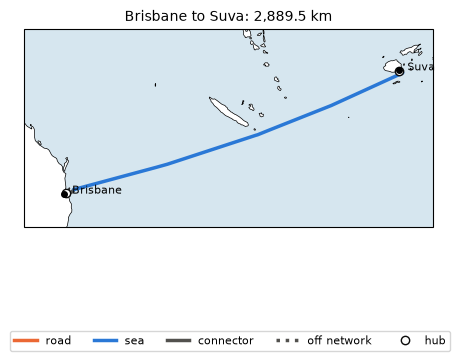

In [15]:
route = all_modes.get_route("Brisbane", "Suva")
print_route("Brisbane to Suva", route)

figure = draw_route_map(-30, 150, -15, 181, {"Brisbane to Suva": route}, ["Brisbane", "Suva"])
plt.show()

## 6. Limit case 1: no route with the chosen modes

No road joins Australia to New Zealand, and no ferry that carries vehicles crosses the Tasman Sea. On the road network, there is no route from Sydney to Auckland. scgraph then raises a `PathNotFoundError`:

In [16]:
try:
    roads.get_route("Sydney", "Auckland")
except PathNotFoundError as error:
    print("PathNotFoundError:", error)

PathNotFoundError: The origin and destination nodes are not connected.


Catch this error where a route may not exist. To get a route, load modes that join the two places. Here, the sea lanes and the ports:

Sydney to Auckland: 2,194.9 km
    off network       0.5 km
    road              8.6 km
    connector        36.6 km
    sea           2,059.1 km
    connector        78.0 km
    road             11.6 km
    off network       0.4 km


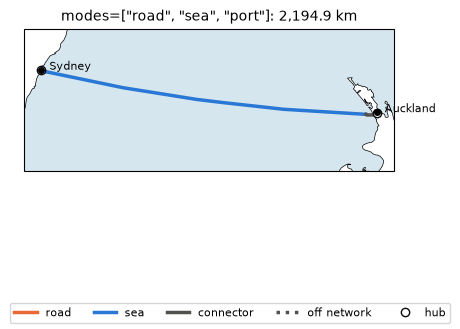

In [17]:
route = roads_and_sea.get_route("Sydney", "Auckland")
print_route("Sydney to Auckland", route)

figure = draw_route_map(-41, 150, -31, 176, {'modes=["road", "sea", "port"]': route}, ["Sydney", "Auckland"])
plt.show()

## 7. Limit case 2: a place far from the network

scgraph joins each place to the nearest node of the loaded network, in a straight line. It does this at any distance, and it raises no error.

Port Moresby is the capital of Papua New Guinea. The network has no railway there. On the rail network, scgraph still returns a route from Sydney to Port Moresby:

In [18]:
rail = Network(modes=["rail"])

route = rail.get_route("Sydney", "Port Moresby")
print_route("Sydney to Port Moresby", route)

Sydney to Port Moresby: 3,499.6 km
    off network       0.4 km
    rail          2,662.5 km
    off network     836.7 km


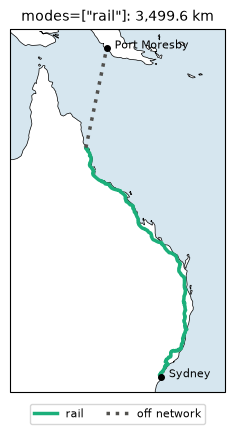

In [19]:
figure = draw_route_map(-35, 140, -8, 156, {'modes=["rail"]': route}, ["Sydney", "Port Moresby"])
plt.show()

The last section is a straight line across the sea. It is part of the length of the route, so the result looks valid, but no train makes this trip.

The same thing happens with any network when a place is outside the area that the network covers. For example, `oceania` has no road outside its rectangle.

**Check the two ends of each route.** The first two points of `coordinate_path` are the origin and the node nearest to it. The last two points are the node nearest to the destination, and the destination. The function below measures these two straight lines. You choose the limit that fits your use.

In [20]:
def get_off_network_km(route):
    """The straight-line distances between the two places of a route and the network, in km."""
    points = route["coordinate_path"]
    return haversine(points[0], points[1]), haversine(points[-2], points[-1])


LIMIT_KM = 25

for origin, destination in [("Sydney", "Perth"), ("Sydney", "Port Moresby")]:
    route = rail.get_route(origin, destination)
    at_origin, at_destination = get_off_network_km(route)
    verdict = "accepted" if max(at_origin, at_destination) <= LIMIT_KM else "refused"
    print(
        f"By rail, {origin} to {destination}: {route['length']:,.1f} km. "
        f"Off the network: {at_origin:.1f} km and {at_destination:.1f} km -> {verdict}"
    )

By rail, Sydney to Perth: 3,950.3 km. Off the network: 0.4 km and 0.0 km -> accepted
By rail, Sydney to Port Moresby: 3,499.6 km. Off the network: 0.4 km and 836.7 km -> refused


## What to remember

- `GeoGraph.load_geograph("oceania")` loads a multimodal network. The other names are in the README of scgraph, section *Network Releases*. `world_multimodal` covers the whole world.
- A route is the shortest in kilometres. It does not count time or price. With all the modes, a long route nearly always takes a flight.
- `modes` loads some modes only. Load a hub mode (`port`, `airport`, `rail_terminal`) with the networks that it joins.
- Each arc has a class. `network_file.read` returns the classes with the arcs, as the class `Network` of this notebook shows.
- When the loaded network has no route between two places, scgraph raises a `PathNotFoundError`.
- When a place is far from the loaded network, scgraph raises no error. Measure the two ends of the route.

To learn how these networks are built, checked and published, read the guide [From open data to a route](https://github.com/connor-makowski/scgraph/blob/main/scgraph/pipelines/README.md).